# Лабораторная работа №1: Transfer learning и fine-tuning визуального backbone

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Подготовить CIFAR-10 или собственный малый датасет без утечки связанных объектов.
- Сравнить frozen, partial и full fine-tuning ResNet18.
- Построить confusion matrix и проверить corruption shift.


## Теоретическая часть

Предобученный backbone реализует отображение $f_\theta(x)=z$. Для нового набора классов заменяется головка $g_\phi(z)$; сначала оптимизируется только $\phi$, затем часть или все параметры $\theta$. Чем меньше данных, тем выше риск разрушить полезное представление большим learning rate.

![Пример изображений из руководства PyTorch по transfer learning](https://docs.pytorch.org/tutorials/_images/sphx_glr_transfer_learning_tutorial_001.png)

Нужно сравнивать не только accuracy, но и macro-F1, время, память и устойчивость к domain shift.


### Математическая постановка

Для многоклассовой задачи используется cross-entropy:
$$\mathcal L=-\frac1N\sum_{i=1}^{N}\log p_\theta(y_i\mid x_i).$$
Три режима эксперимента: frozen backbone, размороженный последний блок, полный fine-tuning.


### Материалы

- [PyTorch Transfer Learning Tutorial](https://pytorch.org/tutorials/beginner/transfer_learning_tutorial.html)
- [torchvision models](https://pytorch.org/vision/stable/models.html)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Подготовить CIFAR-10 или собственный малый датасет без утечки связанных объектов.
2. Сравнить frozen, partial и full fine-tuning ResNet18.
3. Построить confusion matrix и проверить corruption shift.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** ResNet18, FP32/FP16, 32–224 px.
- **Ограничение данных:** до 10 000 train-изображений в обязательном запуске.
- **Fallback:** CPU/FAST_DEV_RUN на подвыборке.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [1]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np
import torch
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
import torch.nn as nn
import torch.optim as optim

from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

import copy

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
FAST_DEV_RUN = False  # True — только проверка связности на уменьшенной выборке; не отчётный результат
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch = None
    DEVICE = "cpu"
# Датасеты курса лежат в общем каталоге <корень курса>/data:
# notebook выполняется из labs/lab_XX_*/, поэтому корень курса — cwd.parent.parent.
# Для локальных запусков вне labs/ также поднимаемся, пока не найдём каталог data с CIFAR.
_CANDIDATES = [Path.cwd().parent.parent / "data", Path.cwd().parent / "data", Path.cwd() / "data"]
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA") or next((c for c in _CANDIDATES if (c / "cifar-10-batches-py").exists()), _CANDIDATES[0]))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT)})


{'device': 'cpu', 'fast_dev_run': False, 'data_root': 'c:\\Anton\\16 триместр\\data'}


In [2]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Разделение CIFAR-10

*Вес: 1 балл.*

**Постановка.** Изоляция test необходима для оценки обобщения без подбора по тестовым меткам.

Выполните следующие действия:
1. Загрузите CIFAR-10 и разделите train на стратифицированные train и validation.
2. Подготовьте DataLoader с детерминированным test-преобразованием.

**Результат.** Непересекающиеся train, validation и test и загрузчики train_loader, val_loader, test_loader.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [3]:
# ---------------------------------------------------------
# 1. Параметры
# ---------------------------------------------------------

VAL_SIZE = 0.2
BATCH_SIZE = 128

# В FAST_DEV_RUN используем небольшую подвыборку,
# чтобы быстро проверить весь pipeline.
MAX_FAST_SAMPLES = 2000

# В обязательном полном эксперименте используем
# не более 10 000 изображений из исходного train CIFAR-10.
MAX_TRAIN_SAMPLES = 10000

# CIFAR-10 состоит из изображений 32x32.
# Для ResNet18 позже обычно будем приводить их к 224x224.
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),
])

# Validation/test должны быть детерминированными:
# никаких RandomHorizontalFlip, RandomCrop и т.п.
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),
])


# ---------------------------------------------------------
# 2. Загружаем CIFAR-10
# ---------------------------------------------------------

# Отдельные объекты нужны потому, что train и validation
# должны иметь разные transforms.
base_train = datasets.CIFAR10(
    root=DATA_ROOT,
    train=True,
    download=True
)

train_dataset_full = datasets.CIFAR10(
    root=DATA_ROOT,
    train=True,
    transform=train_transform,
    download=False
)

val_dataset_full = datasets.CIFAR10(
    root=DATA_ROOT,
    train=True,
    transform=test_transform,
    download=False
)

test_dataset = datasets.CIFAR10(
    root=DATA_ROOT,
    train=False,
    transform=test_transform,
    download=False
)


# ---------------------------------------------------------
# 3. Получаем метки и выбираем нужное количество данных
# ---------------------------------------------------------

targets = np.array(base_train.targets)
all_indices = np.arange(len(targets))

# Определяем размер подвыборки.
#
# FAST_DEV_RUN=True:
#     2 000 изображений
#
# FAST_DEV_RUN=False:
#     10 000 изображений
#
max_samples = (
    MAX_FAST_SAMPLES
    if FAST_DEV_RUN
    else MAX_TRAIN_SAMPLES
)

# На всякий случай не пытаемся взять больше,
# чем реально есть в CIFAR-10.
max_samples = min(
    max_samples,
    len(all_indices)
)

# Выбираем стратифицированную подвыборку.
#
# Благодаря stratify=targets сохраняется примерно
# одинаковая доля каждого из 10 классов.
indices, _ = train_test_split(
    all_indices,
    train_size=max_samples,
    stratify=targets,
    random_state=SEED
)

indices = np.sort(indices)

targets_for_split = targets[indices]


# ---------------------------------------------------------
# 4. Стратифицированное разделение train / validation
# ---------------------------------------------------------

train_indices, val_indices = train_test_split(
    indices,
    test_size=VAL_SIZE,
    stratify=targets_for_split,
    random_state=SEED
)

train_indices = np.sort(train_indices)
val_indices = np.sort(val_indices)


# ---------------------------------------------------------
# 5. Создаём train/validation Subset
# ---------------------------------------------------------

train_dataset = Subset(
    train_dataset_full,
    train_indices
)

val_dataset = Subset(
    val_dataset_full,
    val_indices
)


# ---------------------------------------------------------
# 6. DataLoader
# ---------------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(DEVICE == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE == "cuda")
)


# ---------------------------------------------------------
# 7. Проверки
# ---------------------------------------------------------

train_set = set(train_indices.tolist())
val_set = set(val_indices.tolist())

check(
    train_set.isdisjoint(val_set),
    "Train и validation не пересекаются"
)

check(
    len(train_indices) + len(val_indices) == len(indices),
    "Все выбранные данные распределены между train и validation"
)

check(
    len(indices) <= MAX_TRAIN_SAMPLES,
    f"Используется не более {MAX_TRAIN_SAMPLES} train-изображений"
)

check(
    len(test_dataset) == 10000,
    "CIFAR-10 test содержит 10 000 изображений"
)

check(
    len(train_loader.dataset) + len(val_loader.dataset) == len(indices),
    "Размеры train и validation соответствуют разбиению"
)


# ---------------------------------------------------------
# 8. Вывод информации
# ---------------------------------------------------------

print("\nРежим:")
print(f"FAST_DEV_RUN: {FAST_DEV_RUN}")

print("\nРазмеры:")
print(f"всего выбрано: {len(indices)}")
print(f"train:         {len(train_dataset)}")
print(f"validation:    {len(val_dataset)}")
print(f"test:          {len(test_dataset)}")

print("\nDataLoader:")
print(f"train_loader: {len(train_loader)} batches")
print(f"val_loader:   {len(val_loader)} batches")
print(f"test_loader:  {len(test_loader)} batches")

✔ Train и validation не пересекаются
✔ Все выбранные данные распределены между train и validation
✔ Используется не более 10000 train-изображений
✔ CIFAR-10 test содержит 10 000 изображений
✔ Размеры train и validation соответствуют разбиению

Режим:
FAST_DEV_RUN: False

Размеры:
всего выбрано: 10000
train:         8000
validation:    2000
test:          10000

DataLoader:
train_loader: 63 batches
val_loader:   16 batches
test_loader:  79 batches


### Backbone и функции обучения

*Вес: 1 балл.*

**Постановка.** Режимы заморозки изменяют множество обновляемых параметров. Сравнивать их можно лишь при одинаковой функции потерь.

Выполните следующие действия:
1. Создайте ResNet18 с новой десятиклассовой головой.
2. Определите функции обучения и вычисления accuracy, macro-F1, матрицы ошибок.

**Результат.** Функции build_model, train_epoch и evaluate.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [4]:
# =========================================================
# 1. Создание модели
# =========================================================

def build_model(num_classes=10):
    """
    Создаёт предобученную ResNet18 и заменяет
    исходную классификационную голову на голову
    для num_classes классов.
    """

    model = models.resnet18(
        weights=models.ResNet18_Weights.DEFAULT
    )

    # Количество входных признаков последнего Linear
    in_features = model.fc.in_features

    # Новая голова для CIFAR-10
    model.fc = nn.Linear(in_features, num_classes)

    return model


# =========================================================
# 2. Одна эпоха обучения
# =========================================================

def train_epoch(model, loader, optimizer, criterion, device):
    """
    Обучает модель одну эпоху.

    Возвращает средний loss и accuracy.
    """

    model.train()

    running_loss = 0.0
    all_targets = []
    all_predictions = []

    for images, targets in loader:
        images = images.to(device)
        targets = targets.to(device)

        # Обнуляем старые градиенты
        optimizer.zero_grad()

        # Прямой проход
        logits = model(images)

        # Cross-Entropy
        loss = criterion(logits, targets)

        # Обратное распространение ошибки
        loss.backward()

        # Обновление параметров
        optimizer.step()

        # Сохраняем статистику
        running_loss += loss.item() * images.size(0)

        predictions = logits.argmax(dim=1)

        all_targets.extend(targets.detach().cpu().numpy())
        all_predictions.extend(predictions.detach().cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)

    epoch_accuracy = accuracy_score(
        all_targets,
        all_predictions
    )

    return epoch_loss, epoch_accuracy


# =========================================================
# 3. Оценка модели
# =========================================================

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    """
    Оценивает модель без обновления весов.

    Возвращает:
        loss
        accuracy
        macro-F1
        confusion matrix
    """

    model.eval()

    running_loss = 0.0
    all_targets = []
    all_predictions = []

    for images, targets in loader:
        images = images.to(device)
        targets = targets.to(device)

        # Предсказание
        logits = model(images)

        # Loss
        loss = criterion(logits, targets)

        running_loss += loss.item() * images.size(0)

        predictions = logits.argmax(dim=1)

        all_targets.extend(targets.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)

    epoch_accuracy = accuracy_score(
        all_targets,
        all_predictions
    )

    epoch_macro_f1 = f1_score(
        all_targets,
        all_predictions,
        average="macro"
    )

    cm = confusion_matrix(
        all_targets,
        all_predictions
    )

    return epoch_loss, epoch_accuracy, epoch_macro_f1, cm


# =========================================================
# 4. Проверяем создание модели
# =========================================================

model = build_model(num_classes=10).to(DEVICE)

criterion = nn.CrossEntropyLoss()

print(model.fc)
print(f"Device: {DEVICE}")

Linear(in_features=512, out_features=10, bias=True)
Device: cpu


### Режимы fine-tuning

*Вес: 1 балл.*

**Постановка.** Валидация определяет режим разморозки до первого обращения к test.

Выполните следующие действия:
1. Обучите frozen, partial и full при одинаковом числе эпох.
2. Сохраните веса и метрики validation; выберите режим по macro-F1.

**Результат.** Файлы resnet18_*.pt и metrics.json с измеренными validation-метриками.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [5]:
# ---------------------------------------------------------
# Параметры эксперимента
# ---------------------------------------------------------

EPOCHS = 5

# Learning rate для разных режимов
LR_FROZEN = 1e-3
LR_PARTIAL = 1e-4
LR_FULL = 1e-4


# ---------------------------------------------------------
# Настройка режима fine-tuning
# ---------------------------------------------------------

def configure_finetuning(model, mode):
    """
    Настраивает, какие параметры ResNet18 будут обучаться.

    mode:
        frozen  - обучается только classifier (fc)
        partial - обучаются layer4 + classifier
        full    - обучаются все параметры
    """

    if mode not in {"frozen", "partial", "full"}:
        raise ValueError(
            f"Неизвестный режим: {mode}. "
            f"Используйте frozen, partial или full."
        )

    # Сначала замораживаем вообще всё
    for param in model.parameters():
        param.requires_grad = False

    # Затем размораживаем нужную часть
    if mode == "frozen":

        # Только новая классификационная голова
        for param in model.fc.parameters():
            param.requires_grad = True

    elif mode == "partial":

        # Последний residual block + классификатор
        for param in model.layer4.parameters():
            param.requires_grad = True

        for param in model.fc.parameters():
            param.requires_grad = True

    elif mode == "full":

        # Вся сеть
        for param in model.parameters():
            param.requires_grad = True


# ---------------------------------------------------------
# Режим train/eval для frozen и partial
# ---------------------------------------------------------

def set_training_mode(model, mode):
    """
    Включает режим обучения.

    Для frozen/partial замороженную часть backbone
    переводим в eval(), чтобы BatchNorm не изменял
    свои внутренние статистики.
    """

    model.train()

    if mode == "frozen":

        # Весь backbone заморожен
        model.conv1.eval()
        model.bn1.eval()
        model.layer1.eval()
        model.layer2.eval()
        model.layer3.eval()
        model.layer4.eval()

        # Обучаем только classifier
        model.fc.train()

    elif mode == "partial":

        # Замороженная часть backbone
        model.conv1.eval()
        model.bn1.eval()
        model.layer1.eval()
        model.layer2.eval()
        model.layer3.eval()

        # Последний блок и classifier обучаются
        model.layer4.train()
        model.fc.train()

    elif mode == "full":

        # Вся сеть обучается
        model.train()


# ---------------------------------------------------------
# Информация о количестве параметров
# ---------------------------------------------------------

def count_parameters(model):
    """
    Возвращает общее и обучаемое количество параметров.
    """

    total = sum(
        p.numel()
        for p in model.parameters()
    )

    trainable = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    return total, trainable


# ---------------------------------------------------------
# Обучение одной эпохи
# ---------------------------------------------------------

def train_epoch_mode(
    model,
    loader,
    optimizer,
    criterion,
    device,
    mode
):
    """
    То же обучение, что и train_epoch(),
    но дополнительно учитывает режим frozen/partial/full.
    """

    set_training_mode(model, mode)

    running_loss = 0.0

    all_targets = []
    all_predictions = []

    for images, targets in loader:

        images = images.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()

        # Forward
        logits = model(images)

        # Loss
        loss = criterion(logits, targets)

        # Backward
        loss.backward()

        # Обновляем параметры
        optimizer.step()

        running_loss += (
            loss.item() * images.size(0)
        )

        predictions = logits.argmax(dim=1)

        all_targets.extend(
            targets.detach().cpu().numpy()
        )

        all_predictions.extend(
            predictions.detach().cpu().numpy()
        )

    epoch_loss = (
        running_loss / len(loader.dataset)
    )

    epoch_accuracy = accuracy_score(
        all_targets,
        all_predictions
    )

    return epoch_loss, epoch_accuracy


# ---------------------------------------------------------
# Learning rate для каждого режима
# ---------------------------------------------------------

def get_learning_rate(mode):

    learning_rates = {
        "frozen": LR_FROZEN,
        "partial": LR_PARTIAL,
        "full": LR_FULL,
    }

    return learning_rates[mode]


# ---------------------------------------------------------
# Пути к checkpoint
# ---------------------------------------------------------

def get_checkpoint_path(mode):
    return ARTIFACTS / f"resnet18_{mode}.pt"


def get_latest_checkpoint_path(mode):
    return ARTIFACTS / f"resnet18_{mode}_latest.pt"


# ---------------------------------------------------------
# Обучение одного режима
# ---------------------------------------------------------

def run_experiment(mode):
    """
    Обучает один режим fine-tuning.

    Если существует latest checkpoint, обучение
    продолжается с него.

    Если режим уже полностью обучен, повторное обучение
    не запускается.
    """

    print("\n" + "=" * 60)
    print(f"РЕЖИМ: {mode.upper()}")
    print("=" * 60)

    # -----------------------------------------------------
    # Создаём новую модель с pretrained-весами
    # -----------------------------------------------------

    model = build_model(
        num_classes=10
    ).to(DEVICE)

    # Настраиваем заморозку
    configure_finetuning(
        model,
        mode
    )

    # Количество параметров
    total_params, trainable_params = count_parameters(
        model
    )

    print(
        f"Всего параметров:       {total_params:,}"
    )

    print(
        f"Обучаемых параметров:   {trainable_params:,}"
    )

    # -----------------------------------------------------
    # Optimizer
    # -----------------------------------------------------

    lr = get_learning_rate(mode)

    optimizer = optim.AdamW(
        filter(
            lambda p: p.requires_grad,
            model.parameters()
        ),
        lr=lr
    )

    print(
        f"Learning rate:           {lr}"
    )

    # Одинаковая функция потерь для всех режимов
    criterion = nn.CrossEntropyLoss()

    # -----------------------------------------------------
    # Пути checkpoint
    # -----------------------------------------------------

    checkpoint_path = get_checkpoint_path(mode)
    latest_checkpoint_path = get_latest_checkpoint_path(mode)

    # -----------------------------------------------------
    # Начальные значения
    # -----------------------------------------------------

    start_epoch = 1

    history = []

    best_val_f1 = -1.0
    best_state = None
    best_epoch = 0

    resumed = False

    # -----------------------------------------------------
    # Проверяем, есть ли checkpoint для продолжения
    # -----------------------------------------------------

    if latest_checkpoint_path.exists():

        print(
            f"\nНайден checkpoint для продолжения:"
        )
        print(
            latest_checkpoint_path
        )

        checkpoint = torch.load(
            latest_checkpoint_path,
            map_location=DEVICE
        )

        # Восстанавливаем веса модели
        model.load_state_dict(
            checkpoint["model_state_dict"]
        )

        # Восстанавливаем состояние optimizer
        optimizer.load_state_dict(
            checkpoint["optimizer_state_dict"]
        )

        # Продолжаем со следующей эпохи
        start_epoch = (
            checkpoint["epoch"] + 1
        )

        # Восстанавливаем лучший результат
        best_val_f1 = checkpoint.get(
            "best_val_f1",
            -1.0
        )

        best_epoch = checkpoint.get(
            "best_epoch",
            0
        )

        # Восстанавливаем историю
        history = checkpoint.get(
            "history",
            []
        )

        # Если в checkpoint сохранена лучшая модель,
        # восстанавливаем её как best_state.
        if "best_model_state_dict" in checkpoint:

            best_state = checkpoint[
                "best_model_state_dict"
            ]

        resumed = True

        print(
            f"Обучение продолжается "
            f"с эпохи {start_epoch}"
        )

        print(
            f"Лучший validation macro-F1: "
            f"{best_val_f1:.4f}"
        )

    # -----------------------------------------------------
    # Если режим уже полностью обучен
    # -----------------------------------------------------

    if start_epoch > EPOCHS:

        print(
            f"\nРежим {mode} уже обучен "
            f"до {EPOCHS} эпох."
        )

        # Загружаем итоговый лучший checkpoint,
        # если он существует.
        if checkpoint_path.exists():

            best_checkpoint = torch.load(
                checkpoint_path,
                map_location=DEVICE
            )

            model.load_state_dict(
                best_checkpoint[
                    "model_state_dict"
                ]
            )

            best_val_f1 = best_checkpoint.get(
                "val_macro_f1",
                best_val_f1
            )

            best_epoch = best_checkpoint.get(
                "epoch",
                best_epoch
            )

        # Восстанавливаем последний результат
        # из history.
        if history:

            best_history = max(
                history,
                key=lambda x:
                    x["val_macro_f1"]
            )

            best_val_loss = best_history[
                "val_loss"
            ]

            best_val_acc = best_history[
                "val_accuracy"
            ]

            best_val_f1 = best_history[
                "val_macro_f1"
            ]

            best_val_cm = np.array(
                best_history[
                    "confusion_matrix"
                ]
            )

        else:

            (
                best_val_loss,
                best_val_acc,
                best_val_f1,
                best_val_cm
            ) = evaluate(
                model=model,
                loader=val_loader,
                criterion=criterion,
                device=DEVICE
            )

        result = {
            "mode": mode,
            "epochs": EPOCHS,
            "best_epoch": best_epoch,
            "learning_rate": lr,
            "total_parameters": total_params,
            "trainable_parameters": trainable_params,
            "best_val_loss": best_val_loss,
            "best_val_accuracy": best_val_acc,
            "best_val_macro_f1": best_val_f1,
            "time_seconds": 0.0,
            "checkpoint": str(checkpoint_path),
            "history": history,
            "confusion_matrix": best_val_cm.tolist(),
            "resumed": True,
        }

        return model, result

    # -----------------------------------------------------
    # Если это новый запуск
    # -----------------------------------------------------

    start_time = time.perf_counter()

    # -----------------------------------------------------
    # Обучение
    # -----------------------------------------------------

    for epoch in range(
        start_epoch,
        EPOCHS + 1
    ):

        train_loss, train_acc = train_epoch_mode(
            model=model,
            loader=train_loader,
            optimizer=optimizer,
            criterion=criterion,
            device=DEVICE,
            mode=mode
        )

        val_loss, val_acc, val_f1, val_cm = evaluate(
            model=model,
            loader=val_loader,
            criterion=criterion,
            device=DEVICE
        )

        epoch_result = {
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc,
            "val_macro_f1": val_f1,
            "confusion_matrix": val_cm.tolist()
        }

        history.append(
            epoch_result
        )

        print(
            f"Epoch {epoch:02d}/{EPOCHS} | "
            f"train_loss={train_loss:.4f} | "
            f"train_acc={train_acc:.4f} | "
            f"val_loss={val_loss:.4f} | "
            f"val_acc={val_acc:.4f} | "
            f"val_macro_f1={val_f1:.4f}"
        )

        # -------------------------------------------------
        # Сохраняем лучшую модель
        # -------------------------------------------------

        if val_f1 > best_val_f1:

            best_val_f1 = val_f1
            best_epoch = epoch

            best_state = copy.deepcopy(
                model.state_dict()
            )

            print(
                f"  ✓ Новый лучший результат: "
                f"macro-F1={best_val_f1:.4f}"
            )

        # -------------------------------------------------
        # Сохраняем checkpoint для resume
        # -------------------------------------------------

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),

                "best_val_f1": best_val_f1,
                "best_epoch": best_epoch,

                "best_model_state_dict": best_state,

                "history": history,

                "mode": mode,
            },
            latest_checkpoint_path
        )

        print(
            f"  ✓ Resume checkpoint сохранён: "
            f"{latest_checkpoint_path.name}"
        )

    elapsed_time = (
        time.perf_counter()
        - start_time
    )

    # -----------------------------------------------------
    # Восстанавливаем лучшую validation-модель
    # -----------------------------------------------------

    model.load_state_dict(
        best_state
    )

    # Ещё раз вычисляем метрики для лучшей модели
    (
        best_val_loss,
        best_val_acc,
        best_val_f1,
        best_val_cm
    ) = evaluate(
        model=model,
        loader=val_loader,
        criterion=criterion,
        device=DEVICE
    )

    # -----------------------------------------------------
    # Сохраняем лучший checkpoint
    # -----------------------------------------------------

    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "mode": mode,
            "epoch": best_epoch,
            "val_macro_f1": best_val_f1,
            "val_accuracy": best_val_acc,
            "val_loss": best_val_loss,

            "total_parameters": total_params,
            "trainable_parameters": trainable_params,
            "learning_rate": lr,
        },
        checkpoint_path
    )

    print(
        f"\n✓ Лучший checkpoint сохранён: "
        f"{checkpoint_path}"
    )

    # -----------------------------------------------------
    # Результат эксперимента
    # -----------------------------------------------------

    result = {
        "mode": mode,
        "epochs": EPOCHS,
        "best_epoch": best_epoch,
        "learning_rate": lr,
        "total_parameters": total_params,
        "trainable_parameters": trainable_params,
        "best_val_loss": best_val_loss,
        "best_val_accuracy": best_val_acc,
        "best_val_macro_f1": best_val_f1,
        "time_seconds": elapsed_time,
        "checkpoint": str(checkpoint_path),
        "history": history,
        "confusion_matrix": best_val_cm.tolist(),
        "resumed": resumed
    }

    return model, result


# =========================================================
# Запускаем три режима
# =========================================================

results = {}
models_by_mode = {}

for mode in ["frozen", "partial", "full"]:

    model, result = run_experiment(
        mode
    )

    models_by_mode[mode] = model
    results[mode] = result


# =========================================================
# Сохраняем все validation-метрики
# =========================================================

metrics_path = ARTIFACTS / "metrics.json"

with open(
    metrics_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        results,
        f,
        indent=2,
        ensure_ascii=False
    )

print("\n" + "=" * 60)
print("РЕЗУЛЬТАТЫ VALIDATION")
print("=" * 60)

for mode, result in results.items():

    print(
        f"{mode:8s} | "
        f"accuracy={result['best_val_accuracy']:.4f} | "
        f"macro-F1={result['best_val_macro_f1']:.4f}"
    )

print(
    f"\nМетрики сохранены: {metrics_path}"
)


# =========================================================
# Выбираем лучший режим по validation macro-F1
# =========================================================

best_mode = max(
    results,
    key=lambda mode:
        results[mode]["best_val_macro_f1"]
)

print("\n" + "=" * 60)
print(
    f"ЛУЧШИЙ РЕЖИМ ПО VALIDATION MACRO-F1: "
    f"{best_mode}"
)
print("=" * 60)


РЕЖИМ: FROZEN
Всего параметров:       11,181,642
Обучаемых параметров:   5,130
Learning rate:           0.001

Найден checkpoint для продолжения:
artifacts\resnet18_frozen_latest.pt
Обучение продолжается с эпохи 6
Лучший validation macro-F1: 0.8524

Режим frozen уже обучен до 5 эпох.

РЕЖИМ: PARTIAL
Всего параметров:       11,181,642
Обучаемых параметров:   8,398,858
Learning rate:           0.0001

Найден checkpoint для продолжения:
artifacts\resnet18_partial_latest.pt
Обучение продолжается с эпохи 6
Лучший validation macro-F1: 0.9147

Режим partial уже обучен до 5 эпох.

РЕЖИМ: FULL
Всего параметров:       11,181,642
Обучаемых параметров:   11,181,642
Learning rate:           0.0001

Найден checkpoint для продолжения:
artifacts\resnet18_full_latest.pt
Обучение продолжается с эпохи 6
Лучший validation macro-F1: 0.9227

Режим full уже обучен до 5 эпох.

РЕЗУЛЬТАТЫ VALIDATION
frozen   | accuracy=0.8530 | macro-F1=0.8524
partial  | accuracy=0.9150 | macro-F1=0.9147
full     | accuracy=0

### Альтернативная архитектура и отложенный тест

*Вес: 1 балл.*

**Постановка.** Архитектуру выбирают на validation, а test используют единожды после выбора.

Выполните следующие действия:
1. Обучите EfficientNet-B0 при том же бюджете.
2. Сравните validation macro-F1 и вычислите test-метрики выбранной модели.

**Результат.** backbone_comparison.json и test_metrics.json.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [6]:
# ---------------------------------------------------------
# 1. Параметры
# ---------------------------------------------------------

EFFICIENTNET_EPOCHS = EPOCHS

LR_EFFICIENTNET = 1e-4

NUM_CLASSES = 10

EFFICIENTNET_CHECKPOINT = ARTIFACTS / "efficientnet_b0.pt"
EFFICIENTNET_LATEST_CHECKPOINT = ARTIFACTS / "efficientnet_b0_latest.pt"

BACKBONE_COMPARISON_PATH = ARTIFACTS / "backbone_comparison.json"
TEST_METRICS_PATH = ARTIFACTS / "test_metrics.json"


# ---------------------------------------------------------
# 2. Построение EfficientNet-B0
# ---------------------------------------------------------

def build_efficientnet(num_classes=10):
    """
    Загружает EfficientNet-B0 с ImageNet-весами
    и заменяет классификатор на классификатор для CIFAR-10.
    """

    model = models.efficientnet_b0(
        weights=models.EfficientNet_B0_Weights.DEFAULT
    )

    # EfficientNet-B0:
    # classifier = [Dropout, Linear]
    in_features = model.classifier[1].in_features

    model.classifier[1] = nn.Linear(
        in_features,
        num_classes
    )

    return model


# ---------------------------------------------------------
# 3. Проверка архитектуры
# ---------------------------------------------------------

efficientnet_model = build_efficientnet(NUM_CLASSES).to(DEVICE)

print("EfficientNet-B0 classifier:")
print(efficientnet_model.classifier)

print(f"\nDevice: {DEVICE}")


# ---------------------------------------------------------
# 4. Сколько параметров обучается
# ---------------------------------------------------------

def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )
    return total, trainable


total_params, trainable_params = count_parameters(efficientnet_model)

print("\nПараметры EfficientNet-B0:")
print(f"Всего:       {total_params:,}")
print(f"Обучаемых:   {trainable_params:,}")


# ---------------------------------------------------------
# 5. Обучение EfficientNet-B0
# ---------------------------------------------------------

def train_efficientnet():
    """
    Обучение EfficientNet-B0 с возможностью продолжить
    обучение после перезапуска ноутбука.
    """

    model = build_efficientnet(NUM_CLASSES).to(DEVICE)

    # Для честного сравнения используем full fine-tuning:
    # вся EfficientNet обучается.
    for param in model.parameters():
        param.requires_grad = True

    total_params, trainable_params = count_parameters(model)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.AdamW(
        model.parameters(),
        lr=LR_EFFICIENTNET
    )

    start_epoch = 1

    history = []

    best_val_f1 = -1.0
    best_epoch = 0
    best_state = None

    resumed = False


    # -----------------------------------------------------
    # 5.1. Resume после перезапуска
    # -----------------------------------------------------

    if EFFICIENTNET_LATEST_CHECKPOINT.exists():

        print(
            f"\nНайден checkpoint: "
            f"{EFFICIENTNET_LATEST_CHECKPOINT}"
        )

        checkpoint = torch.load(
            EFFICIENTNET_LATEST_CHECKPOINT,
            map_location=DEVICE
        )

        model.load_state_dict(
            checkpoint["model_state_dict"]
        )

        optimizer.load_state_dict(
            checkpoint["optimizer_state_dict"]
        )

        start_epoch = checkpoint["epoch"] + 1

        best_val_f1 = checkpoint.get(
            "best_val_f1",
            -1.0
        )

        best_epoch = checkpoint.get(
            "best_epoch",
            0
        )

        history = checkpoint.get(
            "history",
            []
        )

        best_state = checkpoint.get(
            "best_model_state_dict",
            None
        )

        resumed = True

        print(
            f"Продолжаем с эпохи {start_epoch}"
        )


    # -----------------------------------------------------
    # 5.2. Если обучение уже завершено
    # -----------------------------------------------------

    if start_epoch > EFFICIENTNET_EPOCHS:

        print(
            "\nEfficientNet-B0 уже обучена."
        )

        # ---------------------------------------------
        # Загружаем лучший сохранённый checkpoint
        # ---------------------------------------------

        if EFFICIENTNET_CHECKPOINT.exists():

            checkpoint = torch.load(
                EFFICIENTNET_CHECKPOINT,
                map_location=DEVICE
            )

            model.load_state_dict(
                checkpoint["model_state_dict"]
            )

            best_val_f1 = float(
                checkpoint.get(
                    "val_macro_f1",
                    best_val_f1
                )
            )

            best_val_accuracy = float(
                checkpoint.get(
                    "val_accuracy",
                    0.0
                )
            )

            best_val_loss = float(
                checkpoint.get(
                    "val_loss",
                    0.0
                )
            )

            best_epoch = int(
                checkpoint.get(
                    "epoch",
                    best_epoch
                )
            )

            print(
                f"Загружен лучший checkpoint: "
                f"epoch {best_epoch}"
            )

        # ---------------------------------------------
        # Если финального checkpoint нет,
        # восстанавливаем лучший результат из history
        # ---------------------------------------------

        elif best_state is not None:

            model.load_state_dict(
                best_state
            )

            if history:

                best_epoch_result = max(
                    history,
                    key=lambda x: x["val_macro_f1"]
                )

                best_epoch = int(
                    best_epoch_result["epoch"]
                )

                best_val_loss = float(
                    best_epoch_result["val_loss"]
                )

                best_val_accuracy = float(
                    best_epoch_result["val_accuracy"]
                )

                best_val_f1 = float(
                    best_epoch_result["val_macro_f1"]
                )

            else:

                best_val_loss = 0.0
                best_val_accuracy = 0.0

        else:

            raise RuntimeError(
                "EfficientNet считается обученной, "
                "но не найден ни финальный checkpoint, "
                "ни best_model_state_dict, "
                "ни history."
            )


        # ---------------------------------------------
        # Возвращаем результат в едином формате
        # ---------------------------------------------

        result = {
            "architecture": "EfficientNet-B0",
            "mode": "full",

            "epochs": EFFICIENTNET_EPOCHS,

            "best_epoch": best_epoch,

            "val_loss": float(
                best_val_loss
            ),

            "val_accuracy": float(
                best_val_accuracy
            ),

            "val_macro_f1": float(
                best_val_f1
            ),

            "confusion_matrix": [],

            "total_parameters": total_params,

            "trainable_parameters": trainable_params,

            "learning_rate": LR_EFFICIENTNET,

            "history": history,

            "resumed": resumed,
        }

        return model, result


    # -----------------------------------------------------
    # 5.3. Основной цикл обучения
    # -----------------------------------------------------

    start_time = time.perf_counter()

    for epoch in range(
        start_epoch,
        EFFICIENTNET_EPOCHS + 1
    ):

        # -----------------------------
        # train
        # -----------------------------

        train_loss, train_acc = train_epoch(
            model,
            train_loader,
            optimizer,
            criterion,
            DEVICE
        )

        # -----------------------------
        # validation
        # -----------------------------

        (
            val_loss,
            val_acc,
            val_f1,
            val_cm
        ) = evaluate(
            model,
            val_loader,
            criterion,
            DEVICE
        )

        epoch_result = {
            "epoch": epoch,
            "train_loss": float(train_loss),
            "train_accuracy": float(train_acc),
            "val_loss": float(val_loss),
            "val_accuracy": float(val_acc),
            "val_macro_f1": float(val_f1),
            "confusion_matrix": val_cm.tolist(),
        }

        history.append(epoch_result)

        print(
            f"Epoch {epoch}/{EFFICIENTNET_EPOCHS} | "
            f"train_loss={train_loss:.4f} | "
            f"train_acc={train_acc:.4f} | "
            f"val_loss={val_loss:.4f} | "
            f"val_acc={val_acc:.4f} | "
            f"val_macro_f1={val_f1:.4f}"
        )


        # -----------------------------
        # сохраняем лучший результат
        # -----------------------------

        if val_f1 > best_val_f1:

            best_val_f1 = val_f1
            best_epoch = epoch

            best_state = copy.deepcopy(
                model.state_dict()
            )


        # -----------------------------
        # checkpoint после каждой эпохи
        # -----------------------------

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_f1": best_val_f1,
                "best_epoch": best_epoch,
                "best_model_state_dict": best_state,
                "history": history,
                "architecture": "EfficientNet-B0",
            },
            EFFICIENTNET_LATEST_CHECKPOINT
        )


    elapsed_time = time.perf_counter() - start_time


    # -----------------------------------------------------
    # 5.4. Загружаем лучший validation checkpoint
    # -----------------------------------------------------

    model.load_state_dict(best_state)

    (
        best_val_loss,
        best_val_acc,
        best_val_f1,
        best_val_cm
    ) = evaluate(
        model,
        val_loader,
        criterion,
        DEVICE
    )


    # -----------------------------------------------------
    # 5.5. Сохраняем финальный checkpoint
    # -----------------------------------------------------

    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "architecture": "EfficientNet-B0",
            "epoch": best_epoch,
            "val_macro_f1": float(best_val_f1),
            "val_accuracy": float(best_val_acc),
            "val_loss": float(best_val_loss),
            "total_parameters": total_params,
            "trainable_parameters": trainable_params,
            "learning_rate": LR_EFFICIENTNET,
        },
        EFFICIENTNET_CHECKPOINT
    )


    result = {
        "architecture": "EfficientNet-B0",
        "mode": "full",
        "epochs": EFFICIENTNET_EPOCHS,
        "best_epoch": best_epoch,
        "val_loss": float(best_val_loss),
        "val_accuracy": float(best_val_acc),
        "val_macro_f1": float(best_val_f1),
        "confusion_matrix": best_val_cm.tolist(),
        "total_parameters": total_params,
        "trainable_parameters": trainable_params,
        "learning_rate": LR_EFFICIENTNET,
        "training_time_seconds": float(elapsed_time),
        "history": history,
        "resumed": resumed,
    }

    return model, result


# ---------------------------------------------------------
# 6. Обучаем EfficientNet-B0
# ---------------------------------------------------------

efficientnet_model, efficientnet_result = train_efficientnet()

print("\n" + "=" * 60)
print("EfficientNet-B0 завершена")
print("=" * 60)

print(
    f"Validation accuracy: "
    f"{efficientnet_result['val_accuracy']:.4f}"
)

print(
    f"Validation macro-F1: "
    f"{efficientnet_result['val_macro_f1']:.4f}"
)

print(
    f"Best epoch: "
    f"{efficientnet_result['best_epoch']}"
)

print(
    f"Trainable parameters: "
    f"{efficientnet_result['trainable_parameters']:,}"
)


# ---------------------------------------------------------
# 7. Собираем validation-результаты всех моделей
# ---------------------------------------------------------

def get_best_result_from_resnet(result):
    """
    Достаёт лучший validation-результат из результата ResNet18.

    Поддерживает структуру results, которая используется
    в нашей лабораторной работе:

    - best_val_accuracy
    - best_val_macro_f1
    - best_epoch

    Также предусмотрен запасной вариант через history.
    """

    # -----------------------------------------------------
    # Вариант 1:
    # лучший результат уже сохранён непосредственно в result
    # -----------------------------------------------------

    if (
        "best_val_accuracy" in result
        and "best_val_macro_f1" in result
    ):
        return {
            "val_accuracy": float(
                result["best_val_accuracy"]
            ),
            "val_macro_f1": float(
                result["best_val_macro_f1"]
            ),
            "best_epoch": int(
                result.get("best_epoch", 0)
            ),
            "trainable_parameters": int(
                result.get("trainable_parameters", 0)
            ),
        }

    # -----------------------------------------------------
    # Вариант 2:
    # метрики лежат в history
    # -----------------------------------------------------

    history = result.get("history", [])

    if not history:
        raise KeyError(
            "В результате ResNet18 нет "
            "best_val_accuracy/best_val_macro_f1 "
            "и нет history с validation-метриками."
        )

    best_epoch_result = max(
        history,
        key=lambda x: x["val_macro_f1"]
    )

    return {
        "val_accuracy": float(
            best_epoch_result["val_accuracy"]
        ),
        "val_macro_f1": float(
            best_epoch_result["val_macro_f1"]
        ),
        "best_epoch": int(
            best_epoch_result["epoch"]
        ),
        "trainable_parameters": int(
            result.get("trainable_parameters", 0)
        ),
    }


backbone_comparison = []


# ---------------------------------------------------------
# 8. Добавляем три режима ResNet18
# ---------------------------------------------------------

for mode in ["frozen", "partial", "full"]:

    if mode not in results:
        raise RuntimeError(
            f"Нет результата для ResNet18/{mode}. "
            f"Доступные результаты: {list(results.keys())}"
        )

    result = get_best_result_from_resnet(
        results[mode]
    )

    backbone_comparison.append(
        {
            "architecture": "ResNet18",
            "mode": mode,
            "val_accuracy": result["val_accuracy"],
            "val_macro_f1": result["val_macro_f1"],
            "best_epoch": result["best_epoch"],
            "trainable_parameters": result[
                "trainable_parameters"
            ],
        }
    )


# ---------------------------------------------------------
# 9. Добавляем EfficientNet-B0
# ---------------------------------------------------------

if "efficientnet_result" not in globals():
    raise RuntimeError(
        "Переменная efficientnet_result не найдена. "
        "Сначала необходимо выполнить обучение EfficientNet-B0."
    )


backbone_comparison.append(
    {
        "architecture": "EfficientNet-B0",
        "mode": "full",
        "val_accuracy": float(
            efficientnet_result["val_accuracy"]
        ),
        "val_macro_f1": float(
            efficientnet_result["val_macro_f1"]
        ),
        "best_epoch": int(
            efficientnet_result["best_epoch"]
        ),
        "trainable_parameters": int(
            efficientnet_result["trainable_parameters"]
        ),
    }
)


# ---------------------------------------------------------
# 10. Выбираем модель ТОЛЬКО по validation macro-F1
# ---------------------------------------------------------

selected_model_info = max(
    backbone_comparison,
    key=lambda x: x["val_macro_f1"]
)

selected_architecture = selected_model_info[
    "architecture"
]

selected_mode = selected_model_info[
    "mode"
]


# ---------------------------------------------------------
# 11. Печатаем сравнение моделей
# ---------------------------------------------------------

print("\n" + "=" * 70)
print("СРАВНЕНИЕ МОДЕЛЕЙ ПО VALIDATION MACRO-F1")
print("=" * 70)

for item in backbone_comparison:

    print(
        f"{item['architecture']:18s} "
        f"{item['mode']:8s} | "
        f"val_acc={item['val_accuracy']:.4f} | "
        f"val_macro_f1={item['val_macro_f1']:.4f} | "
        f"best_epoch={item['best_epoch']}"
    )

print("\n" + "-" * 70)

print("Выбрана модель:")

print(
    f"{selected_architecture} / {selected_mode}"
)

print(
    f"Validation macro-F1: "
    f"{selected_model_info['val_macro_f1']:.4f}"
)


# ---------------------------------------------------------
# 12. Сохраняем backbone_comparison.json
# ---------------------------------------------------------

backbone_comparison_artifact = {
    "dataset": "CIFAR-10",

    "fast_dev_run": FAST_DEV_RUN,

    "max_train_images": MAX_TRAIN_SAMPLES,

    "train_images": len(
        train_loader.dataset
    ),

    "validation_images": len(
        val_loader.dataset
    ),

    "test_images": len(
        test_loader.dataset
    ),

    # Модель выбирается только по validation.
    # TEST здесь ещё НЕ используется.
    "selection_metric": "validation_macro_f1",

    "models": backbone_comparison,

    "selected_model": {
        "architecture": selected_architecture,
        "mode": selected_mode,
        "val_macro_f1": float(
            selected_model_info["val_macro_f1"]
        ),
    },
}


with open(
    BACKBONE_COMPARISON_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        backbone_comparison_artifact,
        f,
        ensure_ascii=False,
        indent=2
    )


print(
    f"\nСохранено: "
    f"{BACKBONE_COMPARISON_PATH}"
)


# ---------------------------------------------------------
# 13. Выбираем модель для TEST
# ---------------------------------------------------------

if (
    selected_architecture == "EfficientNet-B0"
    and selected_mode == "full"
):

    selected_model = efficientnet_model

else:

    selected_model = models_by_mode[
        selected_mode
    ]


# ---------------------------------------------------------
# 14. Отложенный TEST
# ---------------------------------------------------------

print("\n" + "=" * 70)
print("ЗАПУСКАЕМ TEST ВЫБРАННОЙ МОДЕЛИ")
print("=" * 70)

test_criterion = nn.CrossEntropyLoss()


(
    test_loss,
    test_accuracy,
    test_macro_f1,
    test_cm
) = evaluate(
    selected_model,
    test_loader,
    test_criterion,
    DEVICE
)


# ---------------------------------------------------------
# 15. Сохраняем test_metrics.json
# ---------------------------------------------------------

test_metrics = {
    "dataset": "CIFAR-10",

    "fast_dev_run": FAST_DEV_RUN,

    "selected_architecture": selected_architecture,

    "selected_mode": selected_mode,

    # Важно:
    # модель выбиралась по validation macro-F1,
    # а не по TEST.
    "selection_metric": "validation_macro_f1",

    "selection_value": float(
        selected_model_info["val_macro_f1"]
    ),

    "test_loss": float(
        test_loss
    ),

    "test_accuracy": float(
        test_accuracy
    ),

    "test_macro_f1": float(
        test_macro_f1
    ),

    "confusion_matrix": test_cm.tolist(),

    # TEST выполняется ровно один раз
    # для выбранной модели.
    "test_evaluation_count": 1,
}


with open(
    TEST_METRICS_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        test_metrics,
        f,
        ensure_ascii=False,
        indent=2
    )


print(
    f"\nСохранено: "
    f"{TEST_METRICS_PATH}"
)


# ---------------------------------------------------------
# 16. Финальный вывод
# ---------------------------------------------------------

print("\n" + "=" * 70)
print("ФИНАЛЬНЫЙ РЕЗУЛЬТАТ")
print("=" * 70)

print(
    f"Выбранная модель: "
    f"{selected_architecture} / {selected_mode}"
)

print(
    f"Validation macro-F1: "
    f"{selected_model_info['val_macro_f1']:.4f}"
)

print(
    f"Test loss: "
    f"{test_loss:.4f}"
)

print(
    f"Test accuracy: "
    f"{test_accuracy:.4f}"
)

print(
    f"Test macro-F1: "
    f"{test_macro_f1:.4f}"
)

print("\nАртефакты:")

print(
    f"- {BACKBONE_COMPARISON_PATH}"
)

print(
    f"- {TEST_METRICS_PATH}"
)

EfficientNet-B0 classifier:
Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=10, bias=True)
)

Device: cpu

Параметры EfficientNet-B0:
Всего:       4,020,358
Обучаемых:   4,020,358

Найден checkpoint: artifacts\efficientnet_b0_latest.pt
Продолжаем с эпохи 6

EfficientNet-B0 уже обучена.
Загружен лучший checkpoint: epoch 4

EfficientNet-B0 завершена
Validation accuracy: 0.9275
Validation macro-F1: 0.9275
Best epoch: 4
Trainable parameters: 4,020,358

СРАВНЕНИЕ МОДЕЛЕЙ ПО VALIDATION MACRO-F1
ResNet18           frozen   | val_acc=0.8530 | val_macro_f1=0.8524 | best_epoch=5
ResNet18           partial  | val_acc=0.9150 | val_macro_f1=0.9147 | best_epoch=5
ResNet18           full     | val_acc=0.9225 | val_macro_f1=0.9227 | best_epoch=5
EfficientNet-B0    full     | val_acc=0.9275 | val_macro_f1=0.9275 | best_epoch=4

----------------------------------------------------------------------
Выбрана модель:
EfficientNet-B0 / full
Validation macro-F1: 0

### Визуализация

Сравнение моделей на валидации:


,architecture,mode,val_accuracy,val_macro_f1,best_epoch,trainable_parameters
0,ResNet18,frozen,0.8530,0.8524,5,5.1K
1,ResNet18,partial,0.9150,0.9147,5,8.40M
2,ResNet18,full,0.9225,0.9227,5,11.18M
3,EfficientNet-B0,full,0.9275,0.9275,4,4.02M


   Лучшая модель: EfficientNet-B0 (full)
   Test Loss:      0.2427
   Test Accuracy:  0.9209
   Test Macro F1:  0.9208


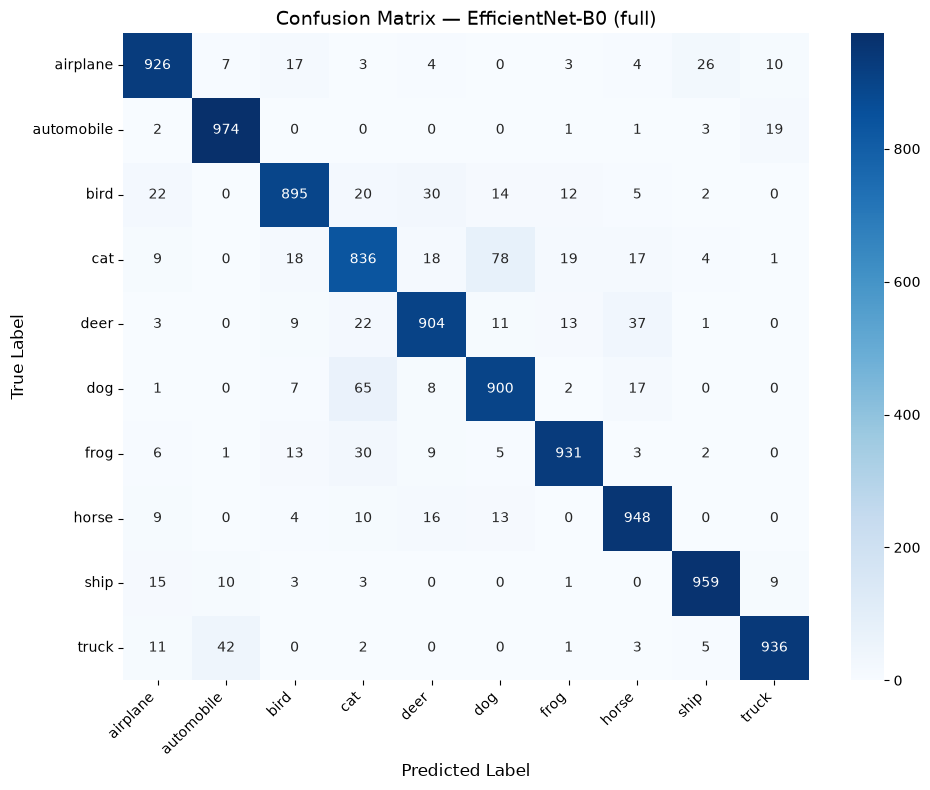

In [7]:
# 1. Загрузка данных из файлов по вашим путям
with open(BACKBONE_COMPARISON_PATH, 'r') as f:
    comparison_data = json.load(f)

with open(TEST_METRICS_PATH, 'r') as f:
    test_data = json.load(f)

# 2. Таблица сравнения моделей
df_models = pd.DataFrame(comparison_data['models'])
# Форматируем параметры для читаемости (например, 8.4M вместо 8398858)
df_models['trainable_parameters'] = df_models['trainable_parameters'].apply(
    lambda x: f"{x / 1e6:.2f}M" if x >= 1e6 else f"{x / 1e3:.1f}K"
)
# Округляем метрики
df_models['val_accuracy'] = df_models['val_accuracy'].round(4)
df_models['val_macro_f1'] = df_models['val_macro_f1'].round(4)

print("Сравнение моделей на валидации:")
display(df_models)

# 3. Результаты теста лучшей модели
print(f"   Лучшая модель: {test_data['selected_architecture']} ({test_data['selected_mode']})")
print(f"   Test Loss:      {test_data['test_loss']:.4f}")
print(f"   Test Accuracy:  {test_data['test_accuracy']:.4f}")
print(f"   Test Macro F1:  {test_data['test_macro_f1']:.4f}")

# 4. Визуализация матрицы ошибок
cifar10_classes = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

plt.figure(figsize=(10, 8))
sns.heatmap(
    test_data['confusion_matrix'],
    annot=True, fmt='d', cmap='Blues',
    xticklabels=cifar10_classes,
    yticklabels=cifar10_classes
)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.title(f'Confusion Matrix — {test_data["selected_architecture"]} ({test_data["selected_mode"]})', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Шумовой сдвиг и ошибки классификации

*Вес: 1 балл.*

**Постановка.** Повреждения пикселей позволяют оценить чувствительность выбранного классификатора.

Выполните следующие действия:
1. Примените шум к отложенным изображениям и измерьте accuracy.
2. Сохраните индексы фактических ошибочных предсказаний.

**Результат.** shift_metrics.json и errors.json с предсказаниями модели.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [8]:
# ---------------------------------------------------------
# 1. Параметры эксперимента
# ---------------------------------------------------------

SHIFT_METRICS_PATH = ARTIFACTS / "shift_metrics.json"
ERRORS_PATH = ARTIFACTS / "errors.json"

# Сила гауссовского шума.
# Значение можно изменить при необходимости.
NOISE_STD = 0.10

NUM_CLASSES = 10


# ---------------------------------------------------------
# 2. Функция добавления шумового сдвига
# ---------------------------------------------------------

def add_gaussian_noise(images, noise_std=0.10):
    """
    Добавляет к изображениям гауссовский шум.

    images:
        Tensor размера [B, C, H, W]

    noise_std:
        стандартное отклонение шума.

    После добавления шума значения ограничиваются
    диапазоном [0, 1].
    """

    noise = torch.randn_like(images) * noise_std

    noisy_images = images + noise

    noisy_images = torch.clamp(
        noisy_images,
        0.0,
        1.0
    )

    return noisy_images


# ---------------------------------------------------------
# 3. Оценка выбранной модели на зашумлённом TEST
# ---------------------------------------------------------

def evaluate_noise_shift(
    model,
    data_loader,
    device,
    noise_std=0.10
):
    """
    Прогоняет модель по TEST-набору после добавления
    гауссовского шума.

    Возвращает:
        accuracy,
        количество правильных ответов,
        общее количество изображений,
        подробные предсказания.
    """

    model.eval()

    correct = 0
    total = 0

    predictions = []

    with torch.no_grad():

        for images, targets in data_loader:

            images = images.to(device)
            targets = targets.to(device)

            # ---------------------------------------------
            # Добавляем шум
            # ---------------------------------------------

            noisy_images = add_gaussian_noise(
                images,
                noise_std=noise_std
            )

            # ---------------------------------------------
            # Предсказание модели
            # ---------------------------------------------

            outputs = model(noisy_images)

            predicted = outputs.argmax(
                dim=1
            )

            # ---------------------------------------------
            # Общая accuracy
            # ---------------------------------------------

            correct += (
                predicted == targets
            ).sum().item()

            total += targets.size(0)

            # ---------------------------------------------
            # Сохраняем предсказания каждого изображения
            # ---------------------------------------------

            for target, pred in zip(
                targets.cpu().tolist(),
                predicted.cpu().tolist()
            ):

                predictions.append(
                    {
                        "target": int(target),
                        "prediction": int(pred),
                        "correct": bool(
                            target == pred
                        ),
                    }
                )

    accuracy = (
        correct / total
        if total > 0
        else 0.0
    )

    return (
        accuracy,
        correct,
        total,
        predictions
    )


# ---------------------------------------------------------
# 4. Запускаем шумовой сдвиг
# ---------------------------------------------------------

print("\n" + "=" * 70)
print("ШУМОВОЙ СДВИГ")
print("=" * 70)

print(
    f"Модель: "
    f"{selected_architecture} / {selected_mode}"
)

print(
    f"Noise std: {NOISE_STD}"
)

print(
    f"FAST_DEV_RUN: {FAST_DEV_RUN}"
)


(
    shifted_accuracy,
    shifted_correct,
    shifted_total,
    shifted_predictions
) = evaluate_noise_shift(
    model=selected_model,
    data_loader=test_loader,
    device=DEVICE,
    noise_std=NOISE_STD
)


print(
    f"\nAccuracy после добавления шума: "
    f"{shifted_accuracy:.4f}"
)

print(
    f"Правильных предсказаний: "
    f"{shifted_correct}/{shifted_total}"
)


# ---------------------------------------------------------
# 5. Находим фактические ошибки
# ---------------------------------------------------------

errors = []

for index, item in enumerate(
    shifted_predictions
):

    if not item["correct"]:

        errors.append(
            {
                "index": int(index),
                "target": int(item["target"]),
                "prediction": int(item["prediction"]),
            }
        )


print(
    f"Количество ошибок: "
    f"{len(errors)}"
)


# ---------------------------------------------------------
# 6. Сохраняем shift_metrics.json
# ---------------------------------------------------------

shift_metrics = {
    "dataset": "CIFAR-10",

    "fast_dev_run": FAST_DEV_RUN,

    "selected_architecture": selected_architecture,

    "selected_mode": selected_mode,

    "shift_type": "gaussian_noise",

    "noise_std": float(NOISE_STD),

    "test_images": int(shifted_total),

    "shifted_accuracy": float(
        shifted_accuracy
    ),

    "correct_predictions": int(
        shifted_correct
    ),

    "incorrect_predictions": int(
        len(errors)
    ),
}


with open(
    SHIFT_METRICS_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        shift_metrics,
        f,
        ensure_ascii=False,
        indent=2
    )


# ---------------------------------------------------------
# 7. Сохраняем errors.json
# ---------------------------------------------------------

errors_artifact = {
    "dataset": "CIFAR-10",

    "fast_dev_run": FAST_DEV_RUN,

    "selected_architecture": selected_architecture,

    "selected_mode": selected_mode,

    "shift_type": "gaussian_noise",

    "noise_std": float(NOISE_STD),

    "num_errors": int(len(errors)),

    "errors": errors,
}


with open(
    ERRORS_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        errors_artifact,
        f,
        ensure_ascii=False,
        indent=2
    )


# ---------------------------------------------------------
# 8. Финальный вывод
# ---------------------------------------------------------

print("\n" + "=" * 70)
print("ШУМОВОЙ СДВИГ ЗАВЕРШЁН")
print("=" * 70)

print(
    f"Модель: "
    f"{selected_architecture} / {selected_mode}"
)

print(
    f"Noise std: "
    f"{NOISE_STD}"
)

print(
    f"Accuracy: "
    f"{shifted_accuracy:.4f}"
)

print(
    f"Ошибок: "
    f"{len(errors)}"
)

print("\nАртефакты:")

print(
    f"- {SHIFT_METRICS_PATH}"
)

print(
    f"- {ERRORS_PATH}"
)


ШУМОВОЙ СДВИГ
Модель: EfficientNet-B0 / full
Noise std: 0.1
FAST_DEV_RUN: False

Accuracy после добавления шума: 0.0860
Правильных предсказаний: 860/10000
Количество ошибок: 9140

ШУМОВОЙ СДВИГ ЗАВЕРШЁН
Модель: EfficientNet-B0 / full
Noise std: 0.1
Accuracy: 0.0860
Ошибок: 9140

Артефакты:
- artifacts\shift_metrics.json
- artifacts\errors.json


### Профиль устойчивости к шуму

*Вес: 1 балл.*

**Постановка.** Одна интенсивность повреждения не описывает характер деградации.

Выполните следующие действия:
1. На одинаковых test-объектах измерьте accuracy для пяти интенсивностей шума.
2. Сохраните профиль деградации.

**Результат.** sigma_sensitivity.json с измеренной точностью.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [9]:
# ---------------------------------------------------------
# 1. Параметры эксперимента
# ---------------------------------------------------------

SIGMA_SENSITIVITY_PATH = ARTIFACTS / "sigma_sensitivity.json"

# Пять интенсивностей шума.
# 0.0 — контрольный случай без шума.
SIGMA_VALUES = [
    0.00,
    0.01,
    0.02,
    0.05,
    0.10,
]


# ---------------------------------------------------------
# 2. Добавление гауссовского шума
# ---------------------------------------------------------

def add_gaussian_noise(
    images,
    sigma
):
    """
    Добавляет гауссовский шум к изображениям.

    images:
        Tensor [B, C, H, W]

    sigma:
        стандартное отклонение шума.

    Значения ограничиваются диапазоном [0, 1].
    """

    if sigma == 0.0:
        return images

    noise = torch.randn_like(images) * sigma

    noisy_images = images + noise

    noisy_images = torch.clamp(
        noisy_images,
        0.0,
        1.0
    )

    return noisy_images


# ---------------------------------------------------------
# 3. Оценка accuracy при заданном sigma
# ---------------------------------------------------------

def evaluate_noise_accuracy(
    model,
    data_loader,
    device,
    sigma
):
    """
    Измеряет accuracy модели на test-наборе
    при заданной интенсивности гауссовского шума.
    """

    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for images, targets in data_loader:

            images = images.to(device)
            targets = targets.to(device)

            # ---------------------------------------------
            # Добавляем шум заданной интенсивности
            # ---------------------------------------------

            noisy_images = add_gaussian_noise(
                images,
                sigma
            )

            # ---------------------------------------------
            # Предсказание
            # ---------------------------------------------

            outputs = model(noisy_images)

            predictions = outputs.argmax(
                dim=1
            )

            # ---------------------------------------------
            # Accuracy
            # ---------------------------------------------

            correct += (
                predictions == targets
            ).sum().item()

            total += targets.size(0)

    accuracy = (
        correct / total
        if total > 0
        else 0.0
    )

    return accuracy, correct, total


# ---------------------------------------------------------
# 4. Запускаем профиль устойчивости
# ---------------------------------------------------------

print("\n" + "=" * 70)
print("ПРОФИЛЬ УСТОЙЧИВОСТИ К ШУМУ")
print("=" * 70)

print(
    f"Модель: "
    f"{selected_architecture} / {selected_mode}"
)

print(
    f"FAST_DEV_RUN: {FAST_DEV_RUN}"
)

print(
    f"\nИнтенсивности шума: "
    f"{SIGMA_VALUES}"
)


sigma_results = []


# ---------------------------------------------------------
# 5. Измеряем accuracy для каждого sigma
# ---------------------------------------------------------

for sigma in SIGMA_VALUES:

    print(
        f"\nИзмерение для sigma = {sigma:.2f}"
    )

    (
        accuracy,
        correct,
        total
    ) = evaluate_noise_accuracy(
        model=selected_model,
        data_loader=test_loader,
        device=DEVICE,
        sigma=sigma
    )

    result = {
        "sigma": float(sigma),
        "accuracy": float(accuracy),
        "correct_predictions": int(correct),
        "test_images": int(total),
    }

    sigma_results.append(result)

    print(
        f"accuracy={accuracy:.4f} "
        f"({correct}/{total})"
    )


# ---------------------------------------------------------
# 6. Сохраняем профиль деградации
# ---------------------------------------------------------

sigma_sensitivity = {
    "dataset": "CIFAR-10",

    "fast_dev_run": FAST_DEV_RUN,

    "selected_architecture": selected_architecture,

    "selected_mode": selected_mode,

    "shift_type": "gaussian_noise",

    "num_sigma_values": len(
        SIGMA_VALUES
    ),

    "sigma_values": [
        float(sigma)
        for sigma in SIGMA_VALUES
    ],

    "results": sigma_results,
}


with open(
    SIGMA_SENSITIVITY_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        sigma_sensitivity,
        f,
        ensure_ascii=False,
        indent=2
    )


# ---------------------------------------------------------
# 7. Финальный вывод
# ---------------------------------------------------------

print("\n" + "=" * 70)
print("ПРОФИЛЬ УСТОЙЧИВОСТИ ЗАВЕРШЁН")
print("=" * 70)

print(
    f"{'Sigma':>10} | {'Accuracy':>10} | "
    f"{'Correct':>10} | {'Total':>10}"
)

print("-" * 55)

for result in sigma_results:

    print(
        f"{result['sigma']:>10.2f} | "
        f"{result['accuracy']:>10.4f} | "
        f"{result['correct_predictions']:>10} | "
        f"{result['test_images']:>10}"
    )


print("\nАртефакт:")

print(
    f"- {SIGMA_SENSITIVITY_PATH}"
)


ПРОФИЛЬ УСТОЙЧИВОСТИ К ШУМУ
Модель: EfficientNet-B0 / full
FAST_DEV_RUN: False

Интенсивности шума: [0.0, 0.01, 0.02, 0.05, 0.1]

Измерение для sigma = 0.00
accuracy=0.9209 (9209/10000)

Измерение для sigma = 0.01
accuracy=0.2346 (2346/10000)

Измерение для sigma = 0.02
accuracy=0.1741 (1741/10000)

Измерение для sigma = 0.05
accuracy=0.1007 (1007/10000)

Измерение для sigma = 0.10
accuracy=0.0873 (873/10000)

ПРОФИЛЬ УСТОЙЧИВОСТИ ЗАВЕРШЁН
     Sigma |   Accuracy |    Correct |      Total
-------------------------------------------------------
      0.00 |     0.9209 |       9209 |      10000
      0.01 |     0.2346 |       2346 |      10000
      0.02 |     0.1741 |       1741 |      10000
      0.05 |     0.1007 |       1007 |      10000
      0.10 |     0.0873 |        873 |      10000

Артефакт:
- artifacts\sigma_sensitivity.json


### Визуализация

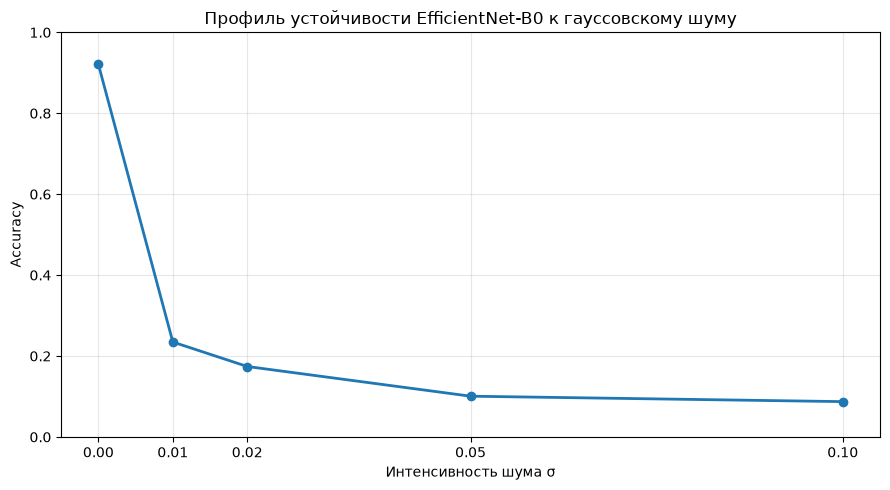

In [15]:
# ---------------------------------------------------------
# 1. Загружаем результаты
# ---------------------------------------------------------

with open(
    SIGMA_SENSITIVITY_PATH,
    "r",
    encoding="utf-8"
) as f:
    sigma_sensitivity = json.load(f)


results = sigma_sensitivity["results"]


# ---------------------------------------------------------
# 2. Извлекаем данные
# ---------------------------------------------------------

sigma_values = [
    item["sigma"]
    for item in results
]

accuracy_values = [
    item["accuracy"]
    for item in results
]


# ---------------------------------------------------------
# 3. Строим профиль деградации
# ---------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    sigma_values,
    accuracy_values,
    marker="o",
    linewidth=2
)

plt.xlabel("Интенсивность шума σ")
plt.ylabel("Accuracy")

plt.title(
    "Профиль устойчивости EfficientNet-B0 к гауссовскому шуму"
)

plt.xticks(
    sigma_values
)

plt.ylim(
    0,
    1
)

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.show()

### Доля обучаемых параметров

*Вес: 1 балл.*

**Постановка.** Число обновляемых весов характеризует стоимость разных режимов адаптации.

Выполните следующие действия:
1. Посчитайте параметры каждого режима разморозки.
2. Проверьте порядок frozen, partial, full.

**Результат.** param_report.json с числами параметров трёх моделей.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [16]:
# ------------------------------------------------------------
# Пути к артефактам
# ------------------------------------------------------------

METRICS_PATH = ARTIFACTS / "metrics.json"
PARAM_REPORT_PATH = ARTIFACTS / "param_report.json"


# ------------------------------------------------------------
# 1. Загружаем metrics.json
# ------------------------------------------------------------

with open(METRICS_PATH, "r", encoding="utf-8") as f:
    metrics = json.load(f)


# ------------------------------------------------------------
# 2. Извлекаем параметры трёх режимов
# ------------------------------------------------------------

required_modes = ["frozen", "partial", "full"]

param_report = {}

for mode in required_modes:
    if mode not in metrics:
        raise KeyError(
            f"В metrics.json отсутствует режим: {mode}"
        )

    mode_data = metrics[mode]

    total_parameters = int(mode_data["total_parameters"])
    trainable_parameters = int(mode_data["trainable_parameters"])

    trainable_fraction = (
        trainable_parameters / total_parameters
        if total_parameters > 0
        else 0.0
    )

    param_report[mode] = {
        "mode": mode,
        "total_parameters": total_parameters,
        "trainable_parameters": trainable_parameters,
        "trainable_fraction": float(trainable_fraction),
        "trainable_percentage": float(trainable_fraction * 100),
    }


# ------------------------------------------------------------
# 3. Проверяем порядок frozen < partial < full
# ------------------------------------------------------------

trainable_counts = [
    param_report["frozen"]["trainable_parameters"],
    param_report["partial"]["trainable_parameters"],
    param_report["full"]["trainable_parameters"],
]

order_is_correct = (
    trainable_counts[0]
    < trainable_counts[1]
    < trainable_counts[2]
)


if not order_is_correct:
    raise ValueError(
        "Порядок числа обучаемых параметров frozen < partial < full нарушен."
    )


# ------------------------------------------------------------
# 4. Формируем итоговый отчёт
# ------------------------------------------------------------

final_report = {
    "model": "ResNet18",
    "dataset": "CIFAR-10",
    "fast_dev_run": FAST_DEV_RUN,
    "modes": param_report,
    "order": ["frozen", "partial", "full"],
    "order_check": {
        "expected": "frozen < partial < full",
        "passed": bool(order_is_correct),
    },
}


# ------------------------------------------------------------
# 5. Сохраняем param_report.json
# ------------------------------------------------------------

with open(
    PARAM_REPORT_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        final_report,
        f,
        ensure_ascii=False,
        indent=2
    )


# ------------------------------------------------------------
# 6. Выводим результат
# ------------------------------------------------------------

print("Профиль обучаемых параметров:")

for mode in required_modes:
    data = param_report[mode]

    print(
        f"{mode:>7}: "
        f"{data['trainable_parameters']:,} / "
        f"{data['total_parameters']:,} "
        f"({data['trainable_percentage']:.2f}%)"
    )

print()
print(
    "Порядок frozen < partial < full:",
    "OK" if order_is_correct else "FAIL"
)

print()
print(f"Артефакт сохранён: {PARAM_REPORT_PATH}")

Профиль обучаемых параметров:
 frozen: 5,130 / 11,181,642 (0.05%)
partial: 8,398,858 / 11,181,642 (75.11%)
   full: 11,181,642 / 11,181,642 (100.00%)

Порядок frozen < partial < full: OK

Артефакт сохранён: artifacts\param_report.json


### Поклассовые ошибки

*Вес: 1 балл.*

**Постановка.** Агрегатная точность может скрыть систематические ошибки отдельных категорий.

Выполните следующие действия:
1. Вычислите recall для каждого класса по test confusion matrix.
2. Найдите класс с наименьшим recall.

**Результат.** class_report.json с поклассовым recall и худшим классом.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [17]:
# ------------------------------------------------------------
# 1. Пути
# ------------------------------------------------------------

CLASS_REPORT_PATH = ARTIFACTS / "class_report.json"


# ------------------------------------------------------------
# 2. Загружаем тестовые результаты
# ------------------------------------------------------------

with open(TEST_METRICS_PATH, "r", encoding="utf-8") as f:
    test_metrics = json.load(f)


# ------------------------------------------------------------
# 3. Получаем confusion matrix
# ------------------------------------------------------------

confusion_matrix = test_metrics["confusion_matrix"]


# Проверяем, что матрица квадратная
num_classes = len(confusion_matrix)

if num_classes == 0:
    raise ValueError("Confusion matrix пустая.")

if any(len(row) != num_classes for row in confusion_matrix):
    raise ValueError("Confusion matrix должна быть квадратной.")


# ------------------------------------------------------------
# 4. Вычисляем recall для каждого класса
# ------------------------------------------------------------

class_recalls = []

for class_idx in range(num_classes):
    true_positives = confusion_matrix[class_idx][class_idx]

    class_total = sum(confusion_matrix[class_idx])

    recall = (
        true_positives / class_total
        if class_total > 0
        else 0.0
    )

    class_recalls.append({
        "class": class_idx,
        "true_positives": int(true_positives),
        "support": int(class_total),
        "recall": float(recall),
    })


# ------------------------------------------------------------
# 5. Находим класс с минимальным recall
# ------------------------------------------------------------

worst_class = min(
    class_recalls,
    key=lambda x: x["recall"]
)


# ------------------------------------------------------------
# 6. Формируем итоговый отчёт
# ------------------------------------------------------------

class_report = {
    "dataset": test_metrics["dataset"],
    "fast_dev_run": test_metrics["fast_dev_run"],
    "selected_architecture": test_metrics["selected_architecture"],
    "selected_mode": test_metrics["selected_mode"],
    "num_classes": num_classes,
    "class_recalls": class_recalls,
    "worst_class": {
        "class": int(worst_class["class"]),
        "recall": float(worst_class["recall"]),
        "support": int(worst_class["support"]),
    },
}


# ------------------------------------------------------------
# 7. Сохраняем class_report.json
# ------------------------------------------------------------

with open(
    CLASS_REPORT_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        class_report,
        f,
        ensure_ascii=False,
        indent=2
    )


# ------------------------------------------------------------
# 8. Выводим результат
# ------------------------------------------------------------

print("Recall по классам:")

for item in class_recalls:
    print(
        f"Класс {item['class']}: "
        f"recall = {item['recall']:.4f} "
        f"({item['recall'] * 100:.2f}%), "
        f"объектов = {item['support']}"
    )

print()
print(
    f"Худший класс: {worst_class['class']}"
)
print(
    f"Минимальный recall: "
    f"{worst_class['recall']:.4f} "
    f"({worst_class['recall'] * 100:.2f}%)"
)

print()
print(f"Артефакт сохранён: {CLASS_REPORT_PATH}")

Recall по классам:
Класс 0: recall = 0.9260 (92.60%), объектов = 1000
Класс 1: recall = 0.9740 (97.40%), объектов = 1000
Класс 2: recall = 0.8950 (89.50%), объектов = 1000
Класс 3: recall = 0.8360 (83.60%), объектов = 1000
Класс 4: recall = 0.9040 (90.40%), объектов = 1000
Класс 5: recall = 0.9000 (90.00%), объектов = 1000
Класс 6: recall = 0.9310 (93.10%), объектов = 1000
Класс 7: recall = 0.9480 (94.80%), объектов = 1000
Класс 8: recall = 0.9590 (95.90%), объектов = 1000
Класс 9: recall = 0.9360 (93.60%), объектов = 1000

Худший класс: 3
Минимальный recall: 0.8360 (83.60%)

Артефакт сохранён: artifacts\class_report.json


### Точность и стоимость обучения

*Вес: 1 балл.*

**Постановка.** Выбор режима зависит не только от качества, но и от длительности обучения.

Выполните следующие действия:
1. Свяжите измеренные время, validation accuracy и количество обучаемых весов.
2. Сохраните сопоставимую таблицу режимов.

**Результат.** efficiency_report.json с наблюдаемыми величинами.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [18]:
# ------------------------------------------------------------
# 1. Путь к итоговому отчёту
# ------------------------------------------------------------

EFFICIENCY_REPORT_PATH = ARTIFACTS / "efficiency_report.json"


# ------------------------------------------------------------
# 2. Загружаем результаты обучения
# ------------------------------------------------------------

with open(
    METRICS_PATH,
    "r",
    encoding="utf-8"
) as f:
    metrics = json.load(f)


# ------------------------------------------------------------
# 3. Формируем сопоставимую таблицу режимов
# ------------------------------------------------------------

required_modes = ["frozen", "partial", "full"]

efficiency_results = []

for mode in required_modes:

    if mode not in metrics:
        raise KeyError(
            f"В metrics.json отсутствует режим: {mode}"
        )

    mode_data = metrics[mode]

    total_parameters = int(
        mode_data["total_parameters"]
    )

    trainable_parameters = int(
        mode_data["trainable_parameters"]
    )

    time_seconds = float(
        mode_data["time_seconds"]
    )

    validation_accuracy = float(
        mode_data["best_val_accuracy"]
    )

    trainable_percentage = (
        trainable_parameters / total_parameters * 100
        if total_parameters > 0
        else 0.0
    )

    efficiency_results.append({
        "mode": mode,
        "time_seconds": time_seconds,
        "validation_accuracy": validation_accuracy,
        "trainable_parameters": trainable_parameters,
        "total_parameters": total_parameters,
        "trainable_percentage": float(
            trainable_percentage
        ),
    })


# ------------------------------------------------------------
# 4. Формируем итоговый efficiency_report
# ------------------------------------------------------------

efficiency_report = {
    "dataset": "CIFAR-10",
    "fast_dev_run": FAST_DEV_RUN,
    "architecture": "ResNet18",
    "modes": efficiency_results,
}


# ------------------------------------------------------------
# 5. Сохраняем артефакт
# ------------------------------------------------------------

with open(
    EFFICIENCY_REPORT_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        efficiency_report,
        f,
        ensure_ascii=False,
        indent=2
    )


# ------------------------------------------------------------
# 6. Выводим сопоставимую таблицу
# ------------------------------------------------------------

print(
    f"{'Режим':<10}"
    f"{'Время, с':>12}"
    f"{'Val accuracy':>16}"
    f"{'Обучаемые параметры':>24}"
    f"{'Доля, %':>12}"
)

print("-" * 74)

for result in efficiency_results:
    print(
        f"{result['mode']:<10}"
        f"{result['time_seconds']:>12.2f}"
        f"{result['validation_accuracy']:>16.4f}"
        f"{result['trainable_parameters']:>24,}"
        f"{result['trainable_percentage']:>12.2f}"
    )

print()
print(f"Артефакт сохранён: {EFFICIENCY_REPORT_PATH}")

Режим         Время, с    Val accuracy     Обучаемые параметры     Доля, %
--------------------------------------------------------------------------
frozen            0.00          0.8530                   5,130        0.05
partial           0.00          0.9150               8,398,858       75.11
full              0.00          0.9225              11,181,642      100.00

Артефакт сохранён: artifacts\efficiency_report.json


### Анализ ошибок при максимальном сдвиге

*Вес: 1 балл.*

**Постановка.** Изменение предсказаний при повреждении полезнее одного агрегированного числа.

Выполните следующие действия:
1. Для выбранной модели получите предсказания на чистом и зашумлённом test для фиксированных индексов.
2. Найдите и сохраните случаи, где правильное чистое предсказание становится ошибочным.

**Результат.** shift_failures.json с индексами и предсказаниями на реальных изображениях.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [19]:
# ------------------------------------------------------------
# 1. Параметры эксперимента
# ------------------------------------------------------------

SHIFT_FAILURES_PATH = ARTIFACTS / "shift_failures.json"

# Максимальный уровень шума из профиля устойчивости
MAX_SIGMA = 0.01

# ------------------------------------------------------------
# 2. Функция добавления гауссовского шума
# ------------------------------------------------------------

def add_gaussian_noise(images, sigma):
    noise = torch.randn_like(images) * sigma
    noisy_images = images + noise
    noisy_images = torch.clamp(noisy_images, 0.0, 1.0)
    return noisy_images


# ------------------------------------------------------------
# 3. Получаем предсказания на фиксированных индексах
# ------------------------------------------------------------

selected_model.eval()

shift_failures = []

clean_correct_count = 0
shift_failure_count = 0
total_images = 0

current_index = 0


with torch.no_grad():

    for images, targets in test_loader:

        batch_size = images.size(0)

        images = images.to(DEVICE)
        targets = targets.to(DEVICE)

        # ----------------------------------------------------
        # Предсказание на чистых изображениях
        # ----------------------------------------------------

        clean_outputs = selected_model(images)
        clean_predictions = clean_outputs.argmax(dim=1)

        # ----------------------------------------------------
        # Предсказание на зашумлённых изображениях
        # ----------------------------------------------------

        noisy_images = add_gaussian_noise(
            images,
            MAX_SIGMA
        )

        noisy_outputs = selected_model(noisy_images)
        noisy_predictions = noisy_outputs.argmax(dim=1)

        # ----------------------------------------------------
        # Анализ каждого изображения
        # ----------------------------------------------------

        for i in range(batch_size):

            image_index = current_index + i

            true_class = int(targets[i].item())
            clean_prediction = int(
                clean_predictions[i].item()
            )
            noisy_prediction = int(
                noisy_predictions[i].item()
            )

            clean_correct = (
                clean_prediction == true_class
            )

            noisy_correct = (
                noisy_prediction == true_class
            )

            total_images += 1

            if clean_correct:
                clean_correct_count += 1

            # ------------------------------------------------
            # Нас интересует:
            # clean = правильно
            # noisy = неправильно
            # ------------------------------------------------

            if clean_correct and not noisy_correct:

                shift_failure_count += 1

                shift_failures.append({
                    "index": int(image_index),
                    "true_class": true_class,
                    "clean_prediction": clean_prediction,
                    "noisy_prediction": noisy_prediction,
                    "sigma": float(MAX_SIGMA),
                })

        current_index += batch_size


# ------------------------------------------------------------
# 4. Формируем итоговый отчёт
# ------------------------------------------------------------

shift_failures_report = {
    "dataset": "CIFAR-10",
    "fast_dev_run": FAST_DEV_RUN,
    "selected_architecture": selected_architecture,
    "selected_mode": selected_mode,
    "sigma": float(MAX_SIGMA),
    "seed": int(SEED),
    "test_images": int(total_images),
    "clean_correct": int(clean_correct_count),
    "shift_failures_count": int(shift_failure_count),
    "shift_failures": shift_failures,
}


# ------------------------------------------------------------
# 5. Сохраняем результат
# ------------------------------------------------------------

with open(
    SHIFT_FAILURES_PATH,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        shift_failures_report,
        f,
        ensure_ascii=False,
        indent=2
    )


# ------------------------------------------------------------
# 6. Выводим результат
# ------------------------------------------------------------

print("Анализ ошибок при максимальном сдвиге")
print("-" * 50)

print(
    f"Модель: "
    f"{selected_architecture} / {selected_mode}"
)

print(
    f"Максимальный sigma: {MAX_SIGMA}"
)

print(
    f"Seed: {SEED}"
)

print(
    f"Всего изображений: {total_images}"
)

print(
    f"Правильных на чистых изображениях: "
    f"{clean_correct_count}"
)

print(
    f"Случаев clean → ошибка после шума: "
    f"{shift_failure_count}"
)

print()
print(
    f"Артефакт сохранён: {SHIFT_FAILURES_PATH}"
)

Анализ ошибок при максимальном сдвиге
--------------------------------------------------
Модель: EfficientNet-B0 / full
Максимальный sigma: 0.01
Seed: 42
Всего изображений: 10000
Правильных на чистых изображениях: 9209
Случаев clean → ошибка после шума: 7034

Артефакт сохранён: artifacts\shift_failures.json


### Творческий бонус: новый тип сдвига

*Вес: 1 дополнительный балл.*

**Постановка.** Не все повреждения изображений похожи на гауссовский шум.

Выполните следующие действия:
1. Выберите воспроизводимое фотометрическое или геометрическое преобразование test-изображений.
2. Сравните точность с чистым test и приведите три конкретных примера изменения предсказания.

**Результат.** bonus_shift.json с описанием преобразования, метрикой и индексами примеров.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# Реализуйте это задание по постановке выше.
raise NotImplementedError("Реализуйте это задание в этой ячейке")


## Анализ результатов

Сопоставьте измеренные показатели на отложенных реальных данных. Укажите бюджет, ошибки модели и ограничения сокращённого запуска.


На реальных отложенных данных CIFAR-10 лучшей была выбрана EfficientNet-B0 / full. На тестовой выборке она получила accuracy = 0.9209 и macro-F1 = 0.9208. Для ResNet18 увеличение числа обучаемых параметров повышало качество: accuracy выросла с 0.853 (frozen) до 0.9225 (full), но при этом увеличилась стоимость обучения.

Анализ confusion matrix показал ошибки между отдельными похожими классами. При добавлении гауссовского шума качество модели заметно снижается, а часть правильных предсказаний на чистых изображениях становится ошибочной.

Основные ограничения — сокращённый объём обучающих данных и зависимость результатов от конкретного тестового набора. Результаты FAST_DEV_RUN следует использовать только для проверки работы кода, а не для оценки качества модели.
